In [1]:
'''
looking at that spinning satellite and what my pipeline does to the streaks that intersect it
'''

'\nlooking at that spinning satellite\n'

In [1]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import os
import pandas as pd

In [2]:
#matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
df = pd.read_csv('/home/3155/best_cands_nosim')

In [4]:
index=25
fits_file = df.loc[index]['filename'] + 'fits.fz'
quadrant = df.loc[index]['quadrant']
hdul = fits.open('/lustre/lrspec/ZTF_data/2022/1020/'+fits_file)
image = hdul[quadrant].data

In [5]:
aname = df.loc[index]['filename'][:-5]+str(quadrant)+'.fits'
xy_array = fits.open('/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/'+aname)[1].data

In [6]:
aname

'ztf_20221020148032_000686_zg_c03_x_4.fits'

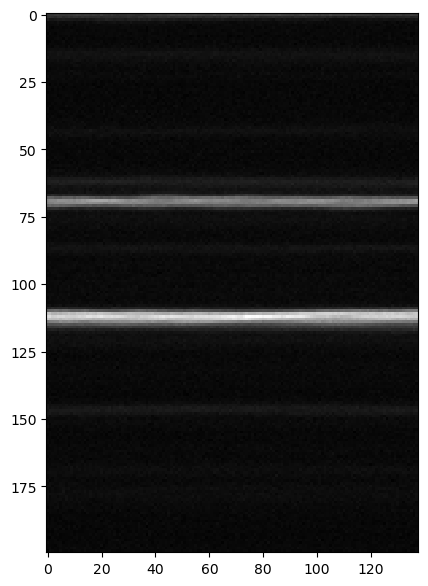

In [13]:
plt.imshow(np.sqrt(image).T[int(df.loc[index]['col_from_nn']-100):int(df.loc[index]['col_from_nn']+100),
           int(df.loc[index]['row_from_nn']-100):int(df.loc[index]['row_from_nn']+100)]
                            )

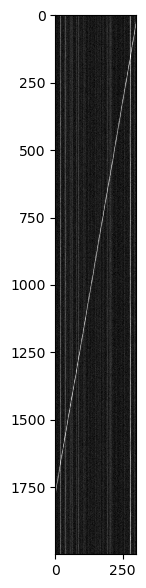

In [33]:
plt.imshow(np.sqrt(image)[0:2000,2200:2500])

In [41]:
import review_findings_functions as rff

(2479.0, 2701.0)
ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist
Number of transient candidates reduced from 4 to 4.
Number of transient candidates reduced from 4 to 2.
ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist_reduced
ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist_reduced_sobelratio_snr
(2221.0, 686.0)
ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist
Number of transient candidates reduced from 3 to 3.
Number of transient candidates reduced from 3 to 2.
ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist_reduced
ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist_reduced_sobelratio_snr
(2238.0, 2065.0)
ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist
Number of transient candidates reduced from 6 to 6.
Number of transient candidates reduced from 6 to 3.
ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist_reduced
ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist_reduced_sobelratio_snr
(2393.0, 1678.0)
ztf_20221020148032_00068

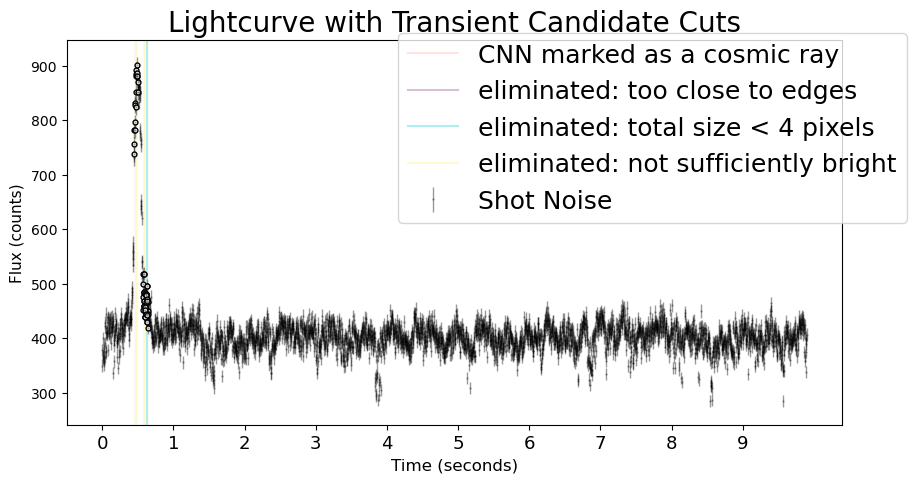

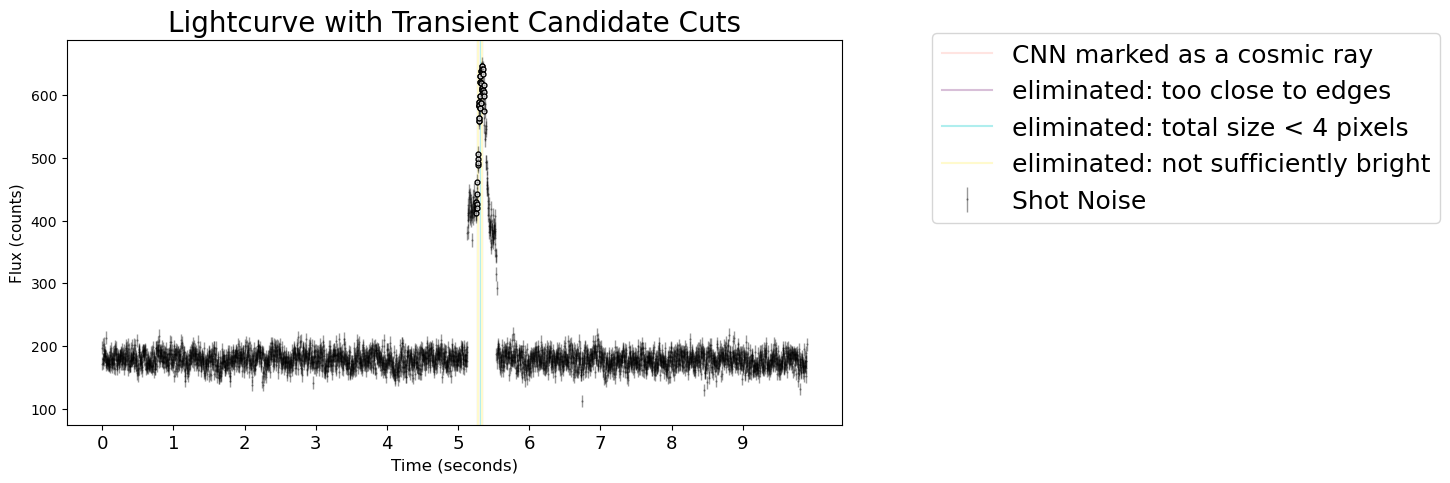

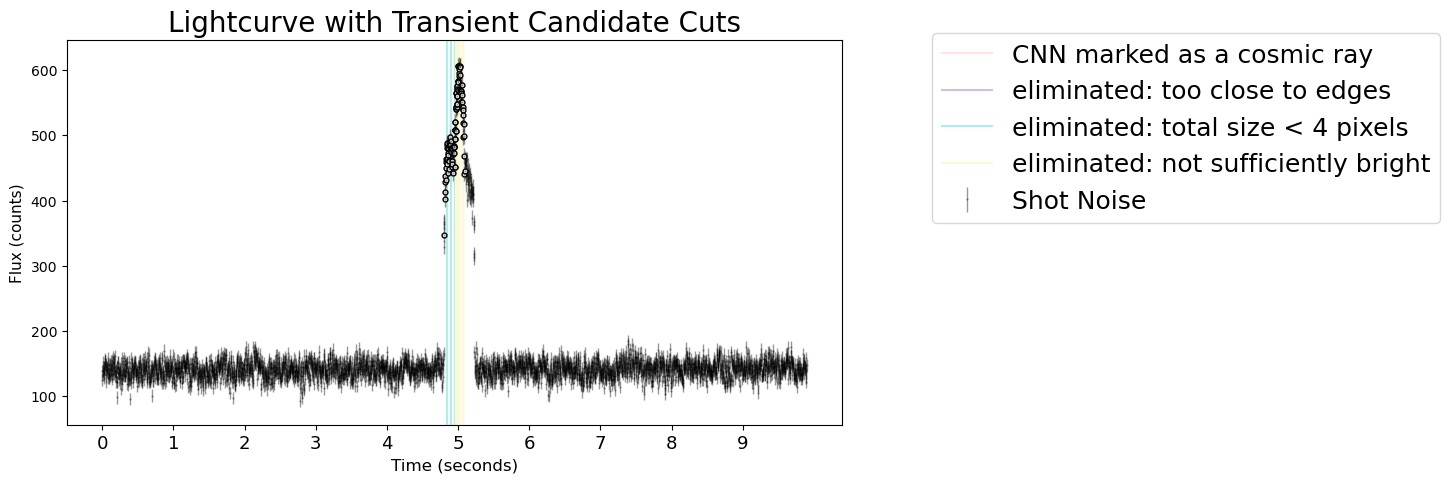

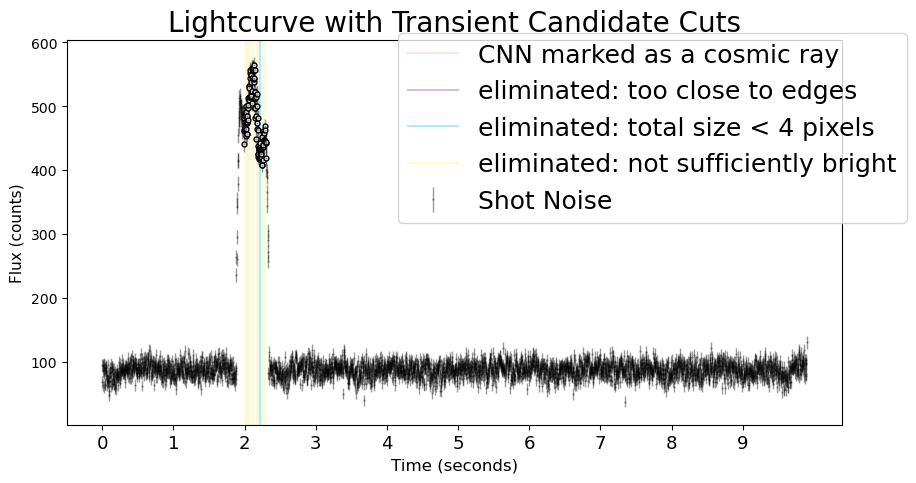

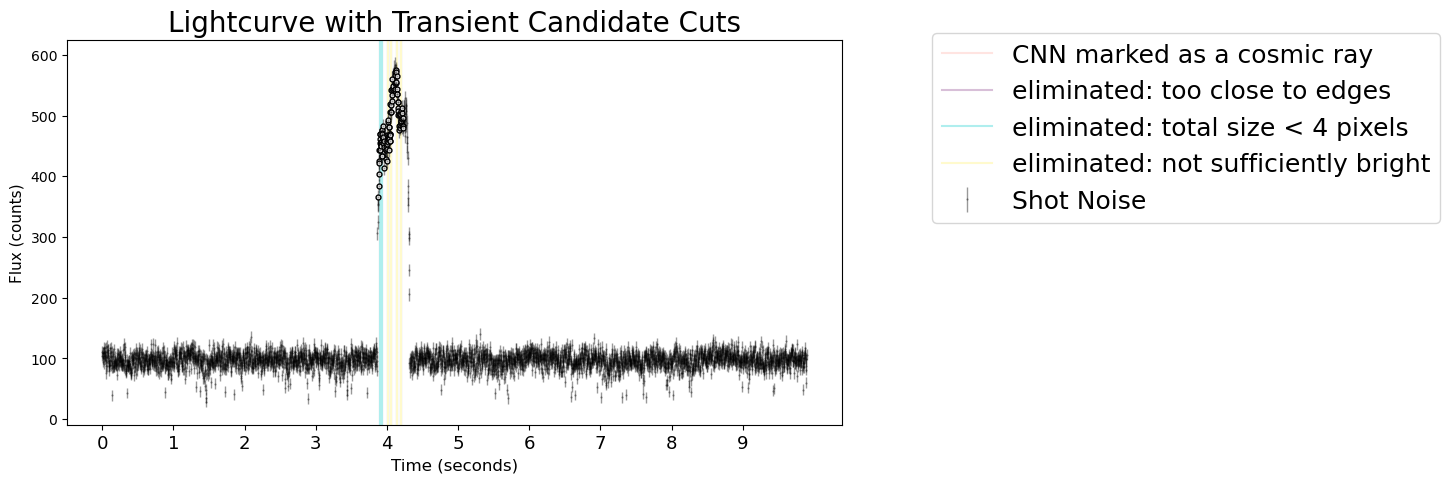

In [43]:
#everything in between x=2200 and x=2500
#hopefully that's in x...small chance it's in y but yes i think x
f'{int(arr[0]):04}'

for arr in xy_array:
    if arr[0]>2200 and arr[0]<2500:
        print(arr)
        lcname = 'lightcurve_'+'ztf_20221020148032_000686_zg_c03_x_0011'+'_4_'+f'{int(arr[0]):04}'+'_'+f'{int(arr[1]):04}'+'.csv'
        rff.plot_lc_from_csv_with_transient_df(lcname, df=None, rowindex=None)

In [44]:
#not sufficiently bright means that they were probably off center
#let's check that

In [47]:
quadrant

4

In [48]:
predsarray = np.load(
    "/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020148032_000686_zg_c03_x_0011._extraction_predsarray_4_predsarray.npy"
)

In [50]:
nrow, ncol = image.shape
wid=10

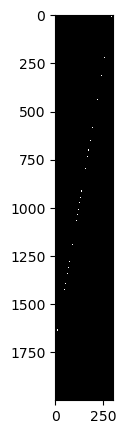

In [54]:
pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)


# In[19]:


plt.imshow((pimg_pos > 0.9999).T[0:2000,2200:2500])
# plt.xlim(row-30,row+10)
# plt.ylim(col-30,col+10)

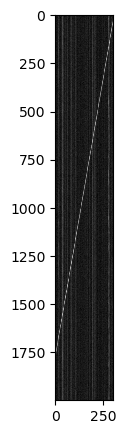

In [53]:
plt.imshow(np.sqrt(image)[0:2000,2200:2500])

In [55]:
for arr in xy_array:
    if arr[0]>2200 and arr[0]<2500:
        print(arr)
        lcname = 'lightcurve_'+'ztf_20221020148032_000686_zg_c03_x_0011'+'_4_'+f'{int(arr[0]):04}'+'_'+f'{int(arr[1]):04}'+'.csv'
        print(lcname)

(2479.0, 2701.0)
lightcurve_ztf_20221020148032_000686_zg_c03_x_0011_4_2479_2701.csv
(2221.0, 686.0)
lightcurve_ztf_20221020148032_000686_zg_c03_x_0011_4_2221_0686.csv
(2238.0, 2065.0)
lightcurve_ztf_20221020148032_000686_zg_c03_x_0011_4_2238_2065.csv
(2393.0, 1678.0)
lightcurve_ztf_20221020148032_000686_zg_c03_x_0011_4_2393_1678.csv
(2288.0, 930.0)
lightcurve_ztf_20221020148032_000686_zg_c03_x_0011_4_2288_0930.csv


In [56]:
transients_df = rff.get_initial_df_for_lc(lcname, tolerance=10)
#    #three things happen:
#    # Reduce based on type != 'cr'
df_nocr = transients_df[transients_df["type"] != "cr"]

df_reduced_edges= rff.reduce_edges(df_nocr, 15)

df_reduced_edges_size4 = rff.reduce_size(df_reduced_edges, 4)
df_reduced_edges_size4
# for i, row in df_reduced_edges_size4.iterrows():
# # print(i)
#     row_num = (int(row['row_from_nn'])+10)
#     if i==df_reduced_edges_size4.index[0]:
#         plt.axvline(x=row_num,c='lemonchiffon', label = "eliminated: not sufficiently bright")
#     else:
#         plt.axvline(x=row_num,c='lemonchiffon')

ztf_20221020148032_000686_zg_c03_x_0011.fits.fz4alllist
Number of transient candidates reduced from 6 to 6.
Number of transient candidates reduced from 6 to 4.


,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size
111,111,ztf_20221020148032_000686_zg_c03_x_0011.,pos,1239.800000,2280.900000,10
112,112,ztf_20221020148032_000686_zg_c03_x_0011.,pos,1252.888889,2278.444444,9
113,113,ztf_20221020148032_000686_zg_c03_x_0011.,pos,1278.000000,2275.000000,5
115,115,ztf_20221020148032_000686_zg_c03_x_0011.,pos,1297.000000,2271.000000,5


In [59]:
import importlib

In [60]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

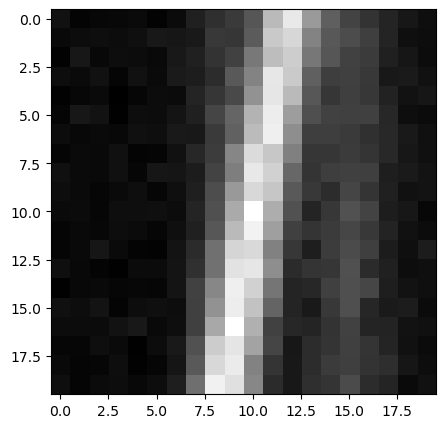

In [65]:
plt.imshow(rff.get_stamp_from_df(115, '1020', df_reduced_edges_size4, quad=4))

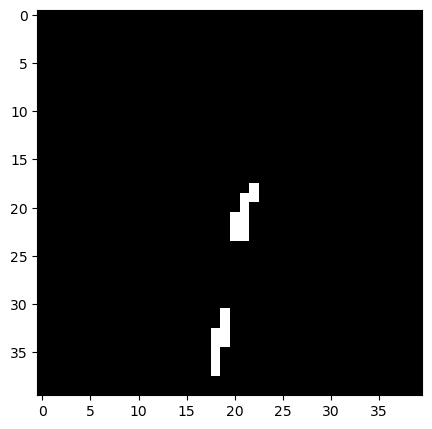

In [66]:
plt.imshow((pimg_pos > 0.9999).T[1239-20:1239+20,2280-20:2280+20])

In [77]:
background = rff.get_image_background(image)

    #subtracting background
imagenobackground = image - np.full(np.shape(image),background)

180.51869


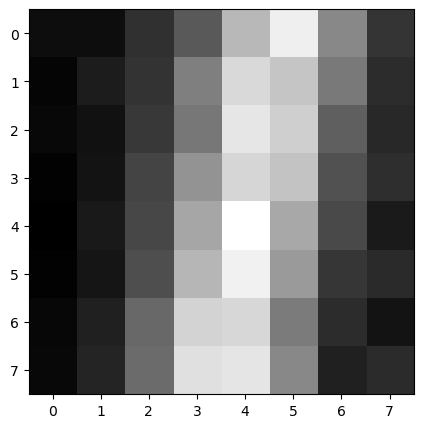

In [78]:
newindex = 115
row = int(df_reduced_edges_size4.loc[newindex]["row_from_nn"]) + 10
col = int(df_reduced_edges_size4.loc[newindex]["col_from_nn"]) + 10
littlerstamp = imagenobackground[row - 4 : row + 4, col - 4 : col + 4]
plt.imshow(littlerstamp)
print(np.max(littlerstamp))

In [ ]:
rff.df_reduced_edges_size4